## Introduction:

I chose the Arlington Real Estate Assessment Payment Summary dataset because it has the financial data of real estate taxes and payment summaries in Arlington County. It's interesting to analyze for trends in property tax totals.
* **Link to dataset page and API documentation:** 
  * [Arlington Open Data Portal](https://datahub-v2.arlingtonva.us/)
  * API Endpoint Used: https://datahub-v2.arlingtonva.us/api/Tax/RealEstateAssessmentPaymentSummary


In [ ]:
import requests
import matplotlib.pyplot as plt
import json
import pandas as pd
from datetime import datetime

# Base URL for Arlington County Real Estate Assessment Payment Summary API
base_url = 'https://datahub-v2.arlingtonva.us/api/Tax/RealEstateAssessmentPaymentSummary?'

## Explore the Data:

**Data Structure:** The data returned from the API is structured as a JSON list

**What does a single object represent?** Each item is an object that represents a unique real estate property's assessment and tax payment summary record in Arlington County



In [16]:
# Get the first 5 records
args = '$top=5'
full_url = base_url + args

# Make the request and parse JSON
response = requests.get(full_url)
sample_data = response.json()

# Print the results formatted as a JSON list
print(json.dumps(sample_data, indent=2))

[
  {
    "realEstateAssessmentPaymentSummaryKey": -1685921631,
    "realEstatePropertyCode": "01001001",
    "taxYearDate": 2016,
    "taxInstallmentName": "1st",
    "displayLabelTypeName": "Levy",
    "taxDueDate": "2016-06-15T00:00:00.000Z",
    "assessedTaxAmt": "706.08",
    "penaltyAmt": "0.00",
    "interestAmt": "0.00",
    "feeAmt": "0.00",
    "totalAmt": "706.08",
    "provalLrsnId": 132,
    "propertyKey": 65025,
    "displayLabelSequenceNbr": 10,
    "assessedSwAmt": "0.00",
    "swPenaltyAmt": "0.00",
    "swInterestAmt": "0.00",
    "swFeeAmt": "0.00",
    "mostRecentPostDate": "2016-04-26T00:00:00.000Z"
  },
  {
    "realEstateAssessmentPaymentSummaryKey": -1682668847,
    "realEstatePropertyCode": "01001001",
    "taxYearDate": 2021,
    "taxInstallmentName": "1st",
    "displayLabelTypeName": "Levy",
    "taxDueDate": "2021-06-15T00:00:00.000Z",
    "assessedTaxAmt": "850.26",
    "penaltyAmt": "0.00",
    "interestAmt": "0.00",
    "feeAmt": "0.00",
    "totalAmt": 

Here are what the API response keys mean:

**realEstateAssessmentPaymentSummaryKey:** A unique database ID/primary key assigned to each individual payment summary record

**realEstatePropertyCode:** A unique parcel or property code identifying a specific real estate property in Arlington County

**propertyKey**: An internal unique database key that links this summary back to the master property record

**provalLrsnId:** An internal Computer-Assisted Mass Appraisal system ID used by the county property assessment office


**taxYearDate:** The tax year associated with the real estate assessment and payment summary

**taxDueDate:** The exact date that the tax payment or installment is due

**mostRecentPostDate:** The timestamp indicating when the record or financial transaction was most recently posted or updated in the county system


**taxInstallmentName:** Indicates which installment period or billing cycle the record represents

**displayLabelTypeName:** The category or classification type of the charge or levy

**displayLabelSequenceNbr:** A sequence number used to order line items correctly on official statements or reports


**assessedTaxAmt:** The core, base amount of real estate tax assessed for the property

**penaltyAmt:** Any financial penalty applied due to late payments or filing delays

**interestAmt:** Any interest charges accumulated on unpaid or overdue balances

**feeAmt:** Any administrative or service fees charged to the account

**totalAmt:** The net total financial amount for the record


**assessedSwAmt:** The assessed stormwater utility fee amount for the property

**swPenaltyAmt:** Any late payment penalty applied specifically to the stormwater utility fee

**swInterestAmt:** Interest accumulated on overdue stormwater utility fees

**swFeeAmt:** Administrative or operational fee amount associated with stormwater services



### Question 1: What are the top ten highest and lowest payment summaries?

In [17]:
args = '$top=2000'
full_url = base_url + args

response = requests.get(full_url)
data = response.json()

# Convert totalAmt from string to float for proper numerical sorting
for item in data:
    item['totalAmt'] = float(item['totalAmt'])

# Sort the records by totalAmt in ascending order
sorted_records = sorted(data, key=lambda x: x['totalAmt'])

# Slice the list to get the 10 least expensive and 10 most expensive
least_expensive = sorted_records[:10]
most_expensive = sorted_records[-10:]

# Use for loops to display the Top 10 Most Expensive payment summaries with exact dates
print("=== TOP 10 MOST EXPENSIVE PAYMENT SUMMARIES ===")
for item in most_expensive:
    # Slice the timestamp string to grab just the YYYY-MM-DD date part
    exact_date = item['taxDueDate'].split('T')[0] if item['taxDueDate'] else "N/A"
    print(f"Record Key: {item['realEstateAssessmentPaymentSummaryKey']} | "
          f"Property Code: {item['realEstatePropertyCode']} | "
          f"Due Date: {exact_date} | "
          f"Total Amount: ${item['totalAmt']:,.2f}")

print("\n=== TOP 10 LEAST EXPENSIVE PAYMENT SUMMARIES ===")
# Use for loops to display the Top 10 Least Expensive payment summaries with exact dates
for item in least_expensive:
    exact_date = item['taxDueDate'].split('T')[0] if item['taxDueDate'] else "N/A"
    print(f"Record Key: {item['realEstateAssessmentPaymentSummaryKey']} | "
          f"Property Code: {item['realEstatePropertyCode']} | "
          f"Due Date: {exact_date} | "
          f"Total Amount: ${item['totalAmt']:,.2f}")


=== TOP 10 MOST EXPENSIVE PAYMENT SUMMARIES ===
Record Key: -1679865095 | Property Code: 01001033 | Due Date: 2024-10-05 | Total Amount: $11,350.08
Record Key: -1668484107 | Property Code: 01001007 | Due Date: 2025-06-15 | Total Amount: $11,504.52
Record Key: -1679098907 | Property Code: 01001032 | Due Date: 2025-06-15 | Total Amount: $11,750.37
Record Key: -1680852051 | Property Code: 01001019 | Due Date: 2025-10-05 | Total Amount: $11,793.76
Record Key: -1672456967 | Property Code: 01001015 | Due Date: 2017-06-15 | Total Amount: $11,937.18
Record Key: -1682135647 | Property Code: 01001021 | Due Date: 2026-10-05 | Total Amount: $12,042.63
Record Key: -1686168103 | Property Code: 01001007 | Due Date: 2026-06-15 | Total Amount: $12,162.15
Record Key: -1681482147 | Property Code: 01001015 | Due Date: 2013-06-15 | Total Amount: $12,362.23
Record Key: -1686377779 | Property Code: 01001015 | Due Date: 2013-10-05 | Total Amount: $12,362.23
Record Key: -1684195203 | Property Code: 01001033 | 

**What I learned:** I learned how to parse through thru the JSON list using for loops and output the statistical extremes by converting the string financial amounts into floats

### Question 2: How can I see payments summaries per year and per month?

In [18]:
args = '$top=5000'
full_url = base_url + args

response = requests.get(full_url)
data = response.json()

# Initialize dictionaries to track counts
yearly_counts = {}

# Dictionary to map month numbers to names
month_names = {
    '01': 'January', '02': 'February', '03': 'March', '04': 'April',
    '05': 'May', '06': 'June', '07': 'July', '08': 'August',
    '09': 'September', '10': 'October', '11': 'November', '12': 'December'
}
monthly_tally = {name: 0 for name in month_names.values()}

# Loop through the data to tally records by year and month
for item in data:

    year = item.get('taxYearDate')
    if year:
        yearly_counts[year] = yearly_counts.get(year, 0) + 1
        
   
    due_date = item.get('taxDueDate')
    if due_date and len(due_date) >= 7:
        month_num = due_date.split('-')[1]
        if month_num in month_names:
            month_name = month_names[month_num]
            monthly_tally[month_name] += 1

# Sort the yearly counts chronologically
sorted_years = sorted(yearly_counts.items())

# Print List 1: Count per Year
print("=== LIST 1: PAYMENT SUMMARIES PER YEAR ===")
for year, count in sorted_years:
    print(f"Tax Year {year}: {count} records")

# Print List 2: Count per Month (across all years)
print("\n=== LIST 2: PAYMENT SUMMARIES PER CALENDAR MONTH (ALL YEARS) ===")
for month, count in monthly_tally.items():
    print(f"{month}: {count} records")


=== LIST 1: PAYMENT SUMMARIES PER YEAR ===
Tax Year 1994: 149 records
Tax Year 1995: 138 records
Tax Year 1996: 118 records
Tax Year 1997: 161 records
Tax Year 1998: 143 records
Tax Year 1999: 116 records
Tax Year 2000: 149 records
Tax Year 2001: 152 records
Tax Year 2002: 148 records
Tax Year 2003: 149 records
Tax Year 2004: 149 records
Tax Year 2005: 142 records
Tax Year 2006: 153 records
Tax Year 2007: 157 records
Tax Year 2008: 145 records
Tax Year 2009: 146 records
Tax Year 2010: 136 records
Tax Year 2011: 136 records
Tax Year 2012: 157 records
Tax Year 2013: 153 records
Tax Year 2014: 144 records
Tax Year 2015: 145 records
Tax Year 2016: 139 records
Tax Year 2017: 157 records
Tax Year 2018: 135 records
Tax Year 2019: 154 records
Tax Year 2020: 133 records
Tax Year 2021: 150 records
Tax Year 2022: 162 records
Tax Year 2023: 130 records
Tax Year 2024: 224 records
Tax Year 2025: 213 records
Tax Year 2026: 217 records

=== LIST 2: PAYMENT SUMMARIES PER CALENDAR MONTH (ALL YEARS) ===


**What I learned:** I learned how to parse the data and seperate it into two different tables using built-in python functions like sorted() and split()

### Question 3: What are the most recent payment updates?

In [19]:
# Sort by mostRecentPostDate descending to fetch the newest entries from the database
args = "$orderby=mostRecentPostDate desc&$top=100"
full_url = base_url + args

response = requests.get(full_url)
data = response.json()

# Get the current year using Python's datetime library
current_year = datetime.now().year

print(f"=== MOST RECENT PAYMENT UPDATES FOR {current_year} ===")
match_count = 0

for item in data:
    post_date_str = item.get('mostRecentPostDate')
    if post_date_str:
        # Convert the API timestamp string into a Python datetime object
        post_date = datetime.fromisoformat(post_date_str.replace('Z', '+00:00'))
        
        # Check if the record's year matches the current year dynamically
        if post_date.year == current_year:
            match_count += 1
            # Format to show the full month name and day (e.g., "November 8")
            month_and_day = post_date.strftime('%B %d')
            
            print(f"{match_count}. Property Code: {item.get('realEstatePropertyCode')} | "
                  f"Tax Year: {item.get('taxYearDate')} | "
                  f"Posted On: {month_and_day}, {current_year} | "
                  f"Total Amount: ${float(item.get('totalAmt', 0)):,.2f}")
            
            # Limit the output to the top 10 current-year records
            if match_count >= 10:
                break


=== MOST RECENT PAYMENT UPDATES FOR 2026 ===
1. Property Code: 16034261 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $34.54
2. Property Code: 15080005 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $149.36
3. Property Code: 02085008 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $7,426.93
4. Property Code: 11061025 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $149.36
5. Property Code: 16034101 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $2,459.41
6. Property Code: 15084031 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $1,871.09
7. Property Code: 16026410 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $34.54
8. Property Code: 14014003 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $298.71
9. Property Code: 16026179 | Tax Year: 2026 | Posted On: November 09, 2026 | Total Amount: $2,420.08
10. Property Code: 14049174 | Tax Year: 2026 | Posted On: 

**What I learned:** How to auto-detect the current year using the datetime module

## Visualization #1: Average tax levy by year


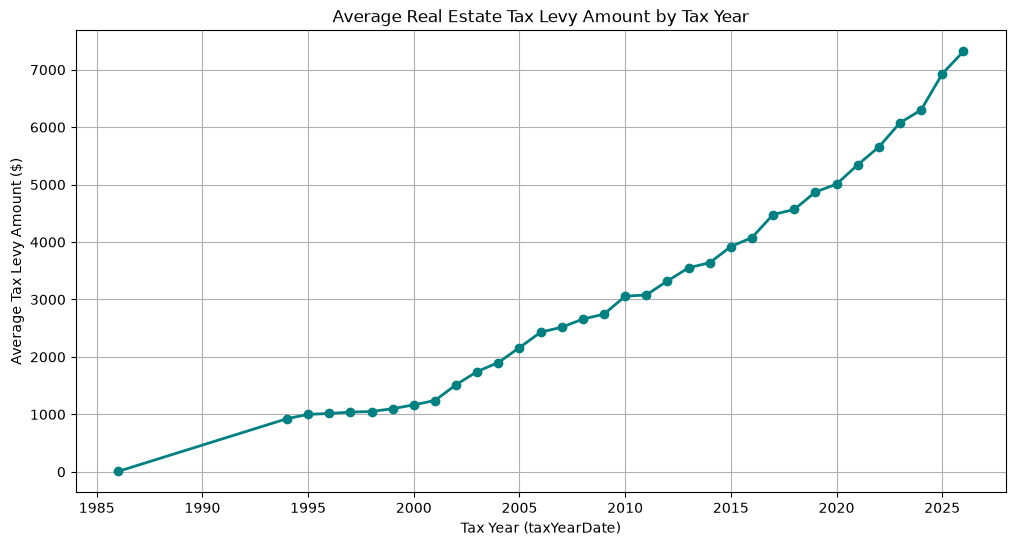

In [20]:
args = '$top=30000'
full_url = base_url + args

response = requests.get(full_url)
data = response.json()

df = pd.DataFrame(data)

df['totalAmt'] = pd.to_numeric(df['totalAmt'], errors='coerce')

df_filtered = df[(df['displayLabelTypeName'] == 'Levy') & (df['totalAmt'] > 0)]

# Group by taxYearDate and calculate the average for actual tax levies
avg_payments = df_filtered.groupby('taxYearDate')['totalAmt'].mean().sort_index()

plt.figure(figsize=(12, 6))
plt.plot(avg_payments.index, avg_payments.values, marker='o', color='teal', linestyle='-', linewidth=2)

# Add titles, labels, and grid for readability
plt.title('Average Real Estate Tax Levy Amount by Tax Year')
plt.xlabel('Tax Year (taxYearDate)')
plt.ylabel('Average Tax Levy Amount ($)')
plt.grid(True)
plt.show()


**What this chart shows:** The average real estate lax levy throughout the years

**Why I chose it:** This line chart reflects the growth of Arlington as a city as more people moved in, which caused a spike in hosuing demand and urban development as shown here


## Visualization #2: Percentage contribution of each tax year

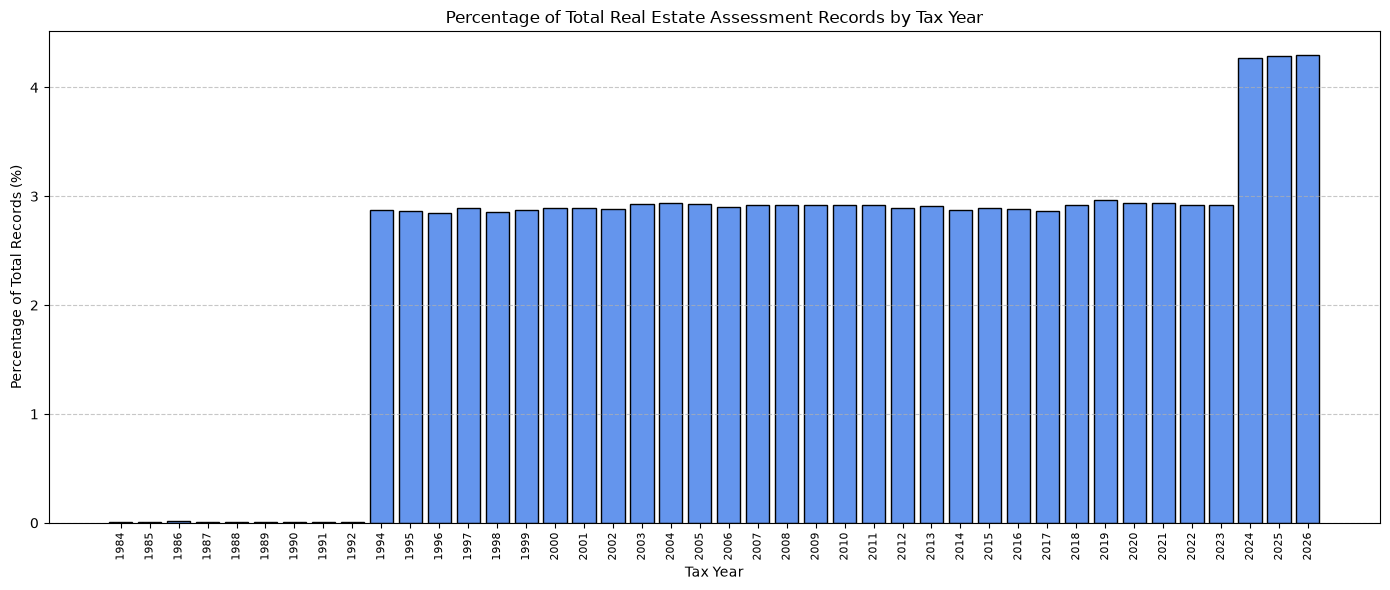

In [21]:
args = '$top=50000'
response = requests.get(base_url + args)
df = pd.DataFrame(response.json())

# Calculate the percentage of total records for each individual tax year
year_counts = df['taxYearDate'].value_counts().sort_index()
year_percentages = (year_counts / len(df)) * 100

# Create the Bar Chart
plt.figure(figsize=(14, 6))
plt.bar(year_percentages.index.astype(str), year_percentages.values, color='cornflowerblue', edgecolor='black')

# Add titles, labels, and grid
plt.title('Percentage of Total Real Estate Assessment Records by Tax Year')
plt.xlabel('Tax Year')
plt.ylabel('Percentage of Total Records (%)')
plt.xticks(rotation=90, fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


**What this chart shows:** This bar graph shows the percentage contribution of each tax year relative to the total assessment records from the dataset

**Why I chose it:** I chose a bar chart because it gives a clear visualization of the distribution of the property records over time, and where increments in the amount of summaries logged has occured


# Process Assumptions, and Issues

### Assumptions Made:
**Representativeness of Sample Data:** I assumed that pulling large query batches (ranging from 1,000 to 30,000 records) from the Arlington County API provides a statistically sound and representative sample of overall county tax trends

**Standard Levy Isolation:** I assumed that filtering records by displayLabelTypeName == 'Levy' reliably isolates core real estate property tax charges from secondary administrative fees, stormwater fees, and credit adjustments

**Temporal Integrity:** I assumed that taxYearDate and mostRecentPostDate accurately reflect the intended tax assessment billing cycle and administrative posting dates without systematic back-dating errors


### Issues and Surprises Encountered:
**The Zero Average Skew:** Initially, plotting average payment amounts resulted in values hovering near zero or dipping negative. I discovered this was because the raw API returns all transaction types, including negative tax relief credits, refunds, and minor utility fees. Fix: Filtered out non-levy items and negative amounts to isolate true tax charges

**Server-Side Sorting Bottlenecks:** Attempting to use server-side sorting ($orderby=taxYearDate asc) on a massive request of 30,000 records caused performance bottlenecks or timeouts. Fix: Removed server-side sorting from the API call and relied on Pandas for fast, reliable client-side sorting and aggregation

**API Parameter Formatting:** I learned that API query parameters have strict syntax with a $ prefix (like $orderby and $top). Forgetting the dollar sign caused the API to ignore the filters

